# Storm analysis — how do we do at the storm peaks?

How well do the reconstructions, and the WHACS boundary goals themselves, capture **storm
peaks** at the Rijkswaterstaat buoys? Sources compared against the buoy Hs:

| Source | What it is |
| --- | --- |
| **WHACS (closest goal)** | Offshore boundary forcing at the goal nearest to the buoy, with no transformation |
| **Bulk metamodel** | `mm.reconstruct(spectral=False)` |
| **Spectral metamodel** | `mm.reconstruct(spectral=True)` (WHACS partitions 0–3) |
| **Dynamic SnapWave** | Reference SnapWave run forced by WHACS (notebook 08), **2010 and 2015 only** |

Everything comes from existing caches (notebooks 08–10); **nothing is reconstructed here**.

1. Storm-peak events at each buoy (buoy Hs above a threshold).
2. Peak scores per buoy and source: peak ratio, bias and timing.
3. Time series of the largest storms.

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from bluemath_tk.core.metrics import compute_metrics
from IPython.display import display
from scipy.signal import find_peaks
from utils.config import SIMULATIONS, resolve
from utils import simulation as sim
from utils import validation as val
from utils import metamodel as mm
from utils import onshore_sites as obs

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)

## Configuration

In [ ]:
period = slice("2010", "2015")  # matches the 09/10 reconstruction caches
offshore_name = "WHACS"
mda_n = 450

# Same sites as notebook 10 (every modelled buoy: ok output sites)
sites = obs.list_snapwave_buoy_sites()

# Buoys analysed, south -> north-east along the coast. AmelanderZeegat_1_2 duplicates
# 1_1, and ZandmoterBoeiNoord has too little data in 2010-2015.
analysis_buoys = [
    "EurogeulE13",
    "IJmuidenMunitiestort_1",
    "PettenMeetraai01",
    "EierlandseGat",
    "StortemelkWest",
    "AmelanderZeegat_1_1",
    "WestereemsWest",
]

# Storm-peak definition
peak_hs_min = 3.0  # buoy Hs threshold (m)
peak_separation_h = 72  # minimum hours between two peaks at the same buoy
peak_window_h = 12  # each source's peak is searched within +/- this window
gap_free_h = 3  # buoy must have data +/- this many hours around its peak

dynamic_path = (
    sim.cases_dir("dynamic")
    / f"Dynamic_Cases_{offshore_name}_2010-2015.nc"
)

# Raw RWS exports, only for Tm-10 in the storm time series (processed files keep hs/dir only)
raw_buoy_files = {
    "EurogeulE13": "inputs/Observations/raw/eurogeul.e13-Eurogeul_E13.nc",
    "IJmuidenMunitiestort_1": "inputs/Observations/raw/ijmuiden.munitiestort.1-IJmuiden_munitiestort_1.nc",
    "PettenMeetraai01": "inputs/Observations/raw/petten.meetraai1-Petten_meetraai_01.nc",
    "EierlandseGat": "inputs/Observations/raw/eierlandsegat-Eierlandse_Gat.nc",
    "StortemelkWest": "inputs/Observations/raw/stortemelk.west-Stortemelk_west.nc",
    "AmelanderZeegat_1_1": "inputs/Observations/raw/amelanderzeegat.1.1-Amelander_zeegat_1_1.nc",
    "WestereemsWest": "inputs/Observations/raw/westereems.west-Westereems_west.nc",
}

## 1 · Load buoys and cached reconstructions

Buoy records are 10-min. They are averaged to hourly values to match the models.

In [ ]:
def buoy_hourly(instrument_id: str) -> pd.Series:
    ds = xr.open_dataset(resolve(f"inputs/Observations/processed/{instrument_id}.nc"))
    return ds["hs"].sel(time=period).to_series().resample("1h").mean()


def buoy_tm10_hourly(raw_path: str) -> pd.Series:
    raw = xr.open_dataset(resolve(raw_path))[
        ["Tm-10", "Tm-10__WaarnemingMetadata_Kwaliteitswaardecode"]
    ].sel(time=period)
    tm = raw["Tm-10"].where(
        raw["Tm-10__WaarnemingMetadata_Kwaliteitswaardecode"] == "00"
    )
    return tm.where((tm > 0) & (tm < 30)).to_series().resample("1h").mean()


obs_hs = pd.DataFrame({b: buoy_hourly(b) for b in analysis_buoys})
obs_tm10 = pd.DataFrame({b: buoy_tm10_hourly(p) for b, p in raw_buoy_files.items()})

recon_kw = dict(
    metamodel="buoys",  # metamodel set fitted on the buoys
    offshore_name=offshore_name,
    sites=sites,
    save_spectra=False,
)
bulk = mm.reconstruct(period, mda_n, spectral=False, **recon_kw)
spectral = mm.reconstruct(period, mda_n, spectral=True, **recon_kw)

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
dynamic = dynamic.sel(sites=bulk.sites.values).load()

offshore_at_buoys, closest_goals = val.load_offshore_hindcast_at_buoys(
    period, sites, variables=["hs", "tp", "dir"]
)
whacs_closest = offshore_at_buoys[f"{offshore_name} (closest goal)"]


def to_frame(ds: xr.Dataset, var: str = "hs") -> pd.DataFrame:
    df = ds[var].to_pandas()
    if df.index.name != "time":
        df = df.T
    return df.rename(columns=lambda s: str(s).removeprefix("buoy_")).reindex(
        obs_hs.index
    )[analysis_buoys]


sources = {
    "WHACS (closest goal)": to_frame(whacs_closest),
    "Bulk metamodel": to_frame(bulk),
    "Spectral metamodel": to_frame(spectral),
    val.DYNAMIC_REFERENCE_LABEL: to_frame(dynamic),
}
source_tp = {
    "WHACS (closest goal)": to_frame(whacs_closest, "tp"),
    "Bulk metamodel": to_frame(bulk, "tp"),
    "Spectral metamodel": to_frame(spectral, "tp"),
}
colors = {
    "Buoy": "k",
    "WHACS (closest goal)": "0.55",
    "Bulk metamodel": "tab:blue",
    "Spectral metamodel": "tab:orange",
    val.DYNAMIC_REFERENCE_LABEL: "tab:green",
}

display(closest_goals)
print("hourly buoy samples:", obs_hs.notna().sum().to_dict())

,site,offshore,goal,distance_m,hindcast_lon,hindcast_lat
0,buoy_AmelanderZeegat_1_1,WHACS,7,54766.0,5.50000,54.00000
1,buoy_AmelanderZeegat_1_2,WHACS,7,54762.0,5.50000,54.00000
2,buoy_EierlandseGat,WHACS,5,27062.1,4.50000,53.50000
3,buoy_EurogeulE13,WHACS,2,48682.9,3.03125,52.03125
4,buoy_IJmuidenMunitiestort_1,WHACS,3,38079.5,3.50000,52.50000
5,buoy_PettenMeetraai01,WHACS,4,43077.9,4.00000,53.00000
6,buoy_StortemelkWest,WHACS,5,38447.2,4.50000,53.50000
7,buoy_WestereemsWest,WHACS,9,43362.6,6.50000,54.00000
8,buoy_ZandmoterBoeiNoord,WHACS,3,67312.2,3.50000,52.50000


hourly buoy samples: {'EurogeulE13': 44792, 'IJmuidenMunitiestort_1': 49750, 'PettenMeetraai01': 17550, 'EierlandseGat': 47503, 'StortemelkWest': 48134, 'AmelanderZeegat_1_1': 27771, 'WestereemsWest': 47715}


## 2 · Storm peaks

A storm peak is a local maximum of buoy Hs above `peak_hs_min`, at least `peak_separation_h`
apart at the same buoy, with no buoy gap within ±`gap_free_h` h. (Buoys often drop out right
at the peak, and a gap there would distort the comparison.) For every source, its own peak is
the maximum within ±`peak_window_h` h of the buoy peak. Amplitude and timing are scored
separately:

- **ratio** = source peak / buoy peak
- **bias** = source peak − buoy peak (m)
- **Δt** = t(source peak) − t(buoy peak) (h, positive = source late)

In [ ]:
def storm_peaks() -> pd.DataFrame:
    rows = []
    win = pd.Timedelta(hours=peak_window_h)
    gap = pd.Timedelta(hours=gap_free_h)
    for b in analysis_buoys:
        o = obs_hs[b]
        idx, _ = find_peaks(
            o.fillna(0).values, height=peak_hs_min, distance=peak_separation_h
        )
        for i in idx:
            t = o.index[i]
            if o[t - gap : t + gap].isna().any():
                continue
            row = {"buoy": b, "time": t, "Buoy": o[t]}
            for name, df in sources.items():
                s = df[b][t - win : t + win]
                if s.notna().sum() < peak_window_h:
                    row[name], row[f"{name} dt"] = np.nan, np.nan
                    continue
                row[name] = s.max()
                row[f"{name} dt"] = (s.idxmax() - t) / pd.Timedelta("1h")
            rows.append(row)
    return pd.DataFrame(rows)


peaks = storm_peaks()
print(f"{len(peaks)} storm peaks with Hs > {peak_hs_min} m")
peaks.groupby("buoy").size().reindex(analysis_buoys).rename("n peaks").to_frame().T

496 storm peaks with Hs > 3.0 m


buoy,EurogeulE13,IJmuidenMunitiestort_1,PettenMeetraai01,EierlandseGat,StortemelkWest,AmelanderZeegat_1_1,WestereemsWest
n peaks,87,94,31,87,65,69,63


In [ ]:
rows = []
for b in [*analysis_buoys, "all buoys"]:
    p = peaks if b == "all buoys" else peaks[peaks.buoy == b]
    for name in sources:
        v = p[[name, "Buoy", f"{name} dt"]].dropna()
        if v.empty:
            continue
        m = compute_metrics(v["Buoy"], v[name], ["bias", "rmse", "rrmse"])
        rows.append(
            {
                "buoy": b,
                "source": name,
                "n": m["n"],
                "median ratio": (v[name] / v["Buoy"]).median(),
                "bias (m)": m["bias"],
                "rmse (m)": m["rmse"],
                "rrmse": m["rrmse"],
                "median Δt (h)": v[f"{name} dt"].median(),
            }
        )
peak_scores = pd.DataFrame(rows).set_index(["buoy", "source"])
peak_scores.round(2)

n  median ratio  bias (m)  rmse (m)  median Δt (h)
buoy                   source                                                                    
EurogeulE13            WHACS (closest goal)   87          0.91     -0.36      0.56            0.0
                       Bulk metamodel         87          0.73     -0.94      1.02            0.0
                       Spectral metamodel     87          0.73     -0.93      1.01            0.0
                       Dynamic SnapWave       27          0.70     -1.04      1.12           -1.0
IJmuidenMunitiestort_1 WHACS (closest goal)   94          0.86     -0.57      0.71            0.0
                       Bulk metamodel         94          0.74     -1.00      1.06            0.0
                       Spectral metamodel     94          0.74     -1.00      1.06            0.0
                       Dynamic SnapWave       29          0.71     -1.09      1.16           -1.0
PettenMeetraai01       WHACS (closest goal)   31          0.85     -0.65      0.86            0.0
                       Bulk metamodel         31          0.73     -1.05      1.15            0.0
                       Spectral metamodel     31          0.73     -1.04      1.14            0.0
                       Dynamic SnapWave       10          0.74     -1.07      1.20           -1.0
EierlandseGat          WHACS (closest goal)   87          0.87     -0.53      0.69            0.0
                       Bulk metamodel         87          0.75     -0.94      1.05            1.0
                       Spectral metamodel     87          0.75     -0.94      1.04            0.0
                       Dynamic SnapWave       27          0.76     -0.93      1.00            0.0
StortemelkWest         WHACS (closest goal)   65          0.96     -0.11      0.33            0.0
                       Bulk metamodel         65          0.80     -0.64      0.82            0.0
                       Spectral metamodel     65          0.80     -0.63      0.81            0.0
                       Dynamic SnapWave       20          0.61     -1.42      1.50            1.0
AmelanderZeegat_1_1    WHACS (closest goal)   69          0.92     -0.26      0.68            0.0
                       Bulk metamodel         69          0.75     -1.00      1.13            1.0
                       Spectral metamodel     69          0.75     -1.00      1.13            1.0
                       Dynamic SnapWave       23          0.69     -1.21      1.35            0.0
WestereemsWest         WHACS (closest goal)   63          0.92     -0.46      0.82           -1.0
                       Bulk metamodel         63          0.79     -0.88      1.07            0.0
                       Spectral metamodel     63          0.79     -0.88      1.07            0.0
                       Dynamic SnapWave       22          0.69     -1.35      1.55            0.0
all buoys              WHACS (closest goal)  496          0.90     -0.41      0.67            0.0
                       Bulk metamodel        496          0.75     -0.92      1.04            0.0
                       Spectral metamodel    496          0.75     -0.92      1.03            0.0
                       Dynamic SnapWave      158          0.71     -1.15      1.27            0.0

The dynamic run only covers 2010 and 2015, so its row above uses fewer storms. Here is the
like-for-like comparison: every source scored on the **same** peaks (those where the dynamic
run exists).

In [ ]:
common = peaks.dropna(subset=list(sources))
like_for_like = pd.DataFrame(
    {
        name: {
            "median ratio": (common[name] / common["Buoy"]).median(),
            **compute_metrics(common["Buoy"], common[name], ["bias", "rmse", "rrmse"]),
        }
        for name in sources
    }
).T.rename(columns={"bias": "bias (m)", "rmse": "rmse (m)"})
like_for_like.round(2)

,n,median ratio,bias (m),rmse (m)
WHACS (closest goal),158.0,0.91,-0.39,0.63
Bulk metamodel,158.0,0.75,-0.91,1.04
Spectral metamodel,158.0,0.75,-0.90,1.03
Dynamic SnapWave,158.0,0.71,-1.15,1.27


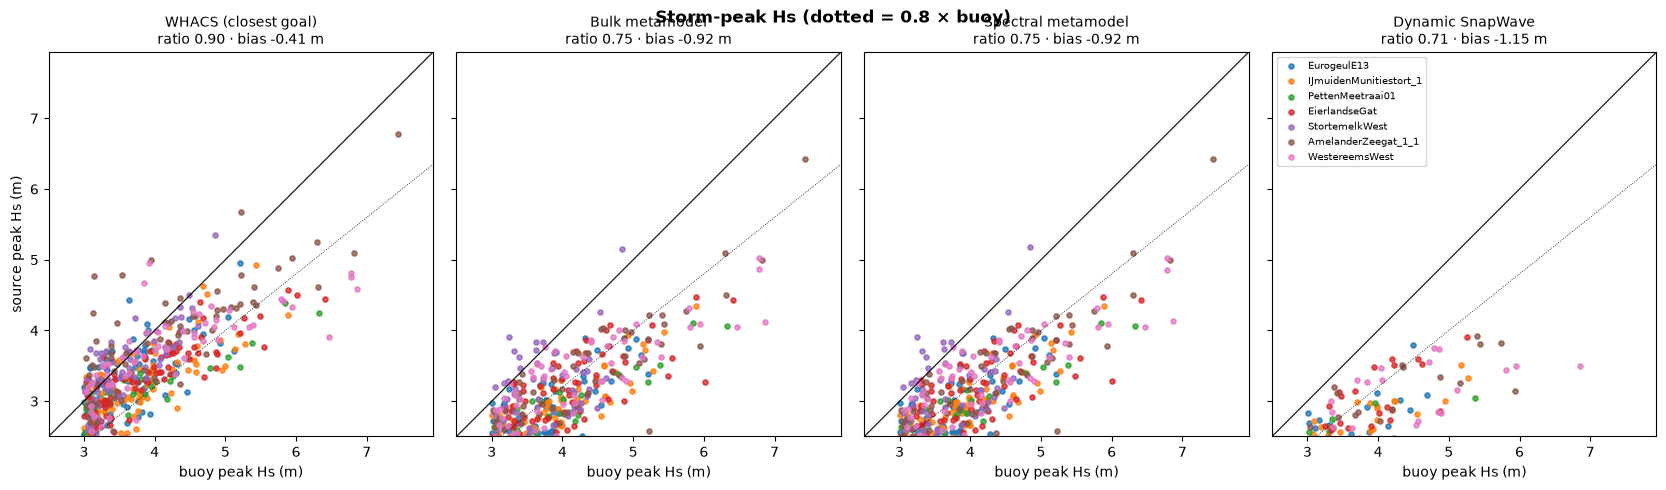

In [ ]:
fig, axes = plt.subplots(
    1, len(sources), figsize=(4.2 * len(sources), 4.4), sharex=True, sharey=True
)
bcols = dict(zip(analysis_buoys, plt.cm.tab10(np.arange(len(analysis_buoys)))))
lim = (peak_hs_min - 0.5, np.nanmax(peaks[["Buoy", *sources]].values) + 0.5)
for ax, name in zip(axes, sources):
    for b in analysis_buoys:
        p = peaks[peaks.buoy == b]
        ax.scatter(p["Buoy"], p[name], s=14, color=bcols[b], label=b, alpha=0.8)
    ax.plot(lim, lim, "k-", lw=0.8)
    ax.plot(lim, [0.8 * x for x in lim], "k:", lw=0.6)
    s = peak_scores.loc[("all buoys", name)]
    ax.set_title(
        f"{name}\nratio {s['median ratio']:.2f} · bias {s['bias (m)']:+.2f} m",
        fontsize=10,
    )
    ax.set(xlim=lim, ylim=lim, xlabel="buoy peak Hs (m)", aspect="equal")
axes[0].set_ylabel("source peak Hs (m)")
axes[-1].legend(fontsize=7, loc="upper left")
plt.tight_layout()
fig.suptitle("Storm-peak Hs (dotted = 0.8 × buoy)", weight="bold", y=1.04)
plt.show()

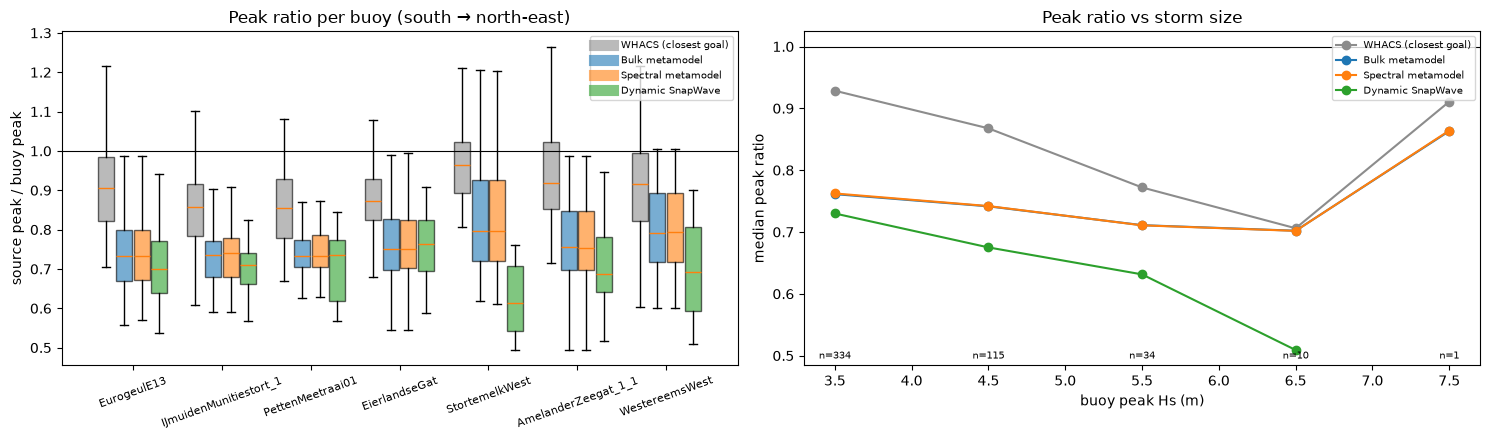

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Peak ratio per buoy and source
ax = axes[0]
pos = np.arange(len(analysis_buoys))
width = 0.8 / len(sources)
for k, name in enumerate(sources):
    data = [
        (peaks[peaks.buoy == b][name] / peaks[peaks.buoy == b]["Buoy"]).dropna().values
        for b in analysis_buoys
    ]
    bp = ax.boxplot(
        data,
        positions=pos + (k - (len(sources) - 1) / 2) * width,
        widths=width * 0.9,
        patch_artist=True,
        showfliers=False,
    )
    for patch in bp["boxes"]:
        patch.set_facecolor(colors[name])
        patch.set_alpha(0.6)
    ax.plot([], [], color=colors[name], lw=8, alpha=0.6, label=name)
ax.axhline(1, color="k", lw=0.8)
ax.set_xticks(pos, analysis_buoys, rotation=20, fontsize=8)
ax.set(
    ylabel="source peak / buoy peak", title="Peak ratio per buoy (south → north-east)"
)
ax.legend(fontsize=7)

# Does the deficit grow with storm size?
ax = axes[1]
bins = np.arange(peak_hs_min, np.ceil(peaks["Buoy"].max()) + 1, 1.0)
centers = 0.5 * (bins[1:] + bins[:-1])
for name in sources:
    r = (peaks[name] / peaks["Buoy"]).groupby(pd.cut(peaks["Buoy"], bins)).median()
    ax.plot(centers, r.values, "o-", color=colors[name], label=name)
ax.axhline(1, color="k", lw=0.8)
counts = pd.cut(peaks["Buoy"], bins).value_counts().sort_index().values
for c, n in zip(centers, counts):
    ax.annotate(
        f"n={n}", (c, 0.02), xycoords=("data", "axes fraction"), ha="center", fontsize=7
    )
ax.set(
    xlabel="buoy peak Hs (m)",
    ylabel="median peak ratio",
    title="Peak ratio vs storm size",
)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 3 · Largest storms

Peaks within 1 day of each other at different buoys are grouped into one storm. Storms are
ranked by their largest buoy Hs (only storms seen by ≥ 3 buoys are kept). For each of the top
storms, the top row shows Hs for every source at three buoys that recorded the peak
(spread from south to north-east). The bottom row shows the buoy **Tm-10** against the source **Tp** (different statistics:
for a single-peaked sea Tm-10 ≈ 0.85–0.9 Tp, so the buoy Tm-10 should sit *below* Tp).

In [9]:
n_top_storms = 4
plot_window = (pd.Timedelta("36h"), pd.Timedelta("48h"))

p = peaks.sort_values("time").reset_index(drop=True)
p["storm"] = (p["time"].diff() > pd.Timedelta("1D")).cumsum()
storms = (
    p.groupby("storm")
    .agg(time=("time", "median"), n_buoys=("buoy", "nunique"), max_hs=("Buoy", "max"))
    .query("n_buoys >= 3")
    .sort_values("max_hs", ascending=False)
    .head(n_top_storms)
)
storms["time"] = storms["time"].dt.round("1h")
display(storms)

,time,n_buoys,max_hs
storm,,,
110,2013-12-05 21:00:00,3,7.436667
144,2015-01-10 20:00:00,4,6.860000
134,2014-10-22 03:00:00,5,6.825000
56,2012-01-05 18:00:00,4,6.780000


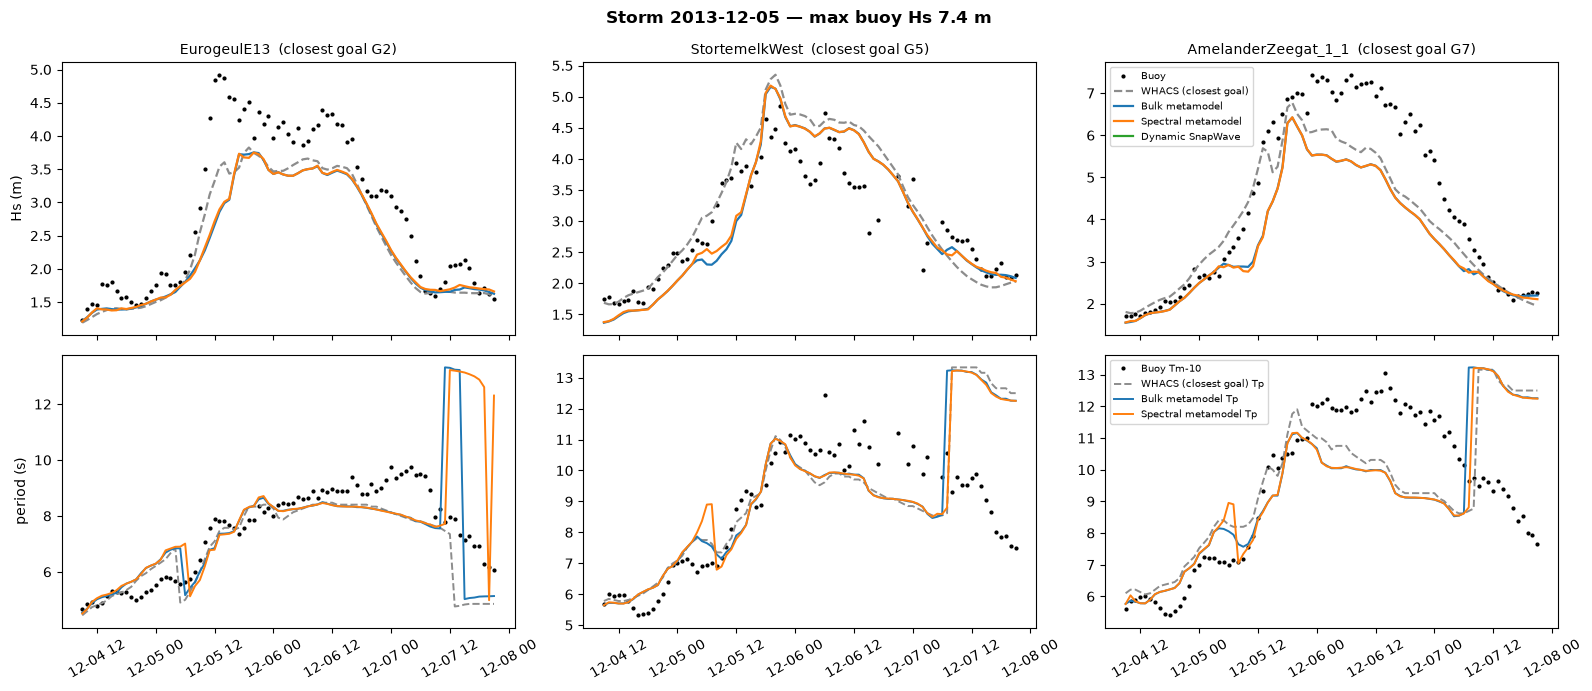

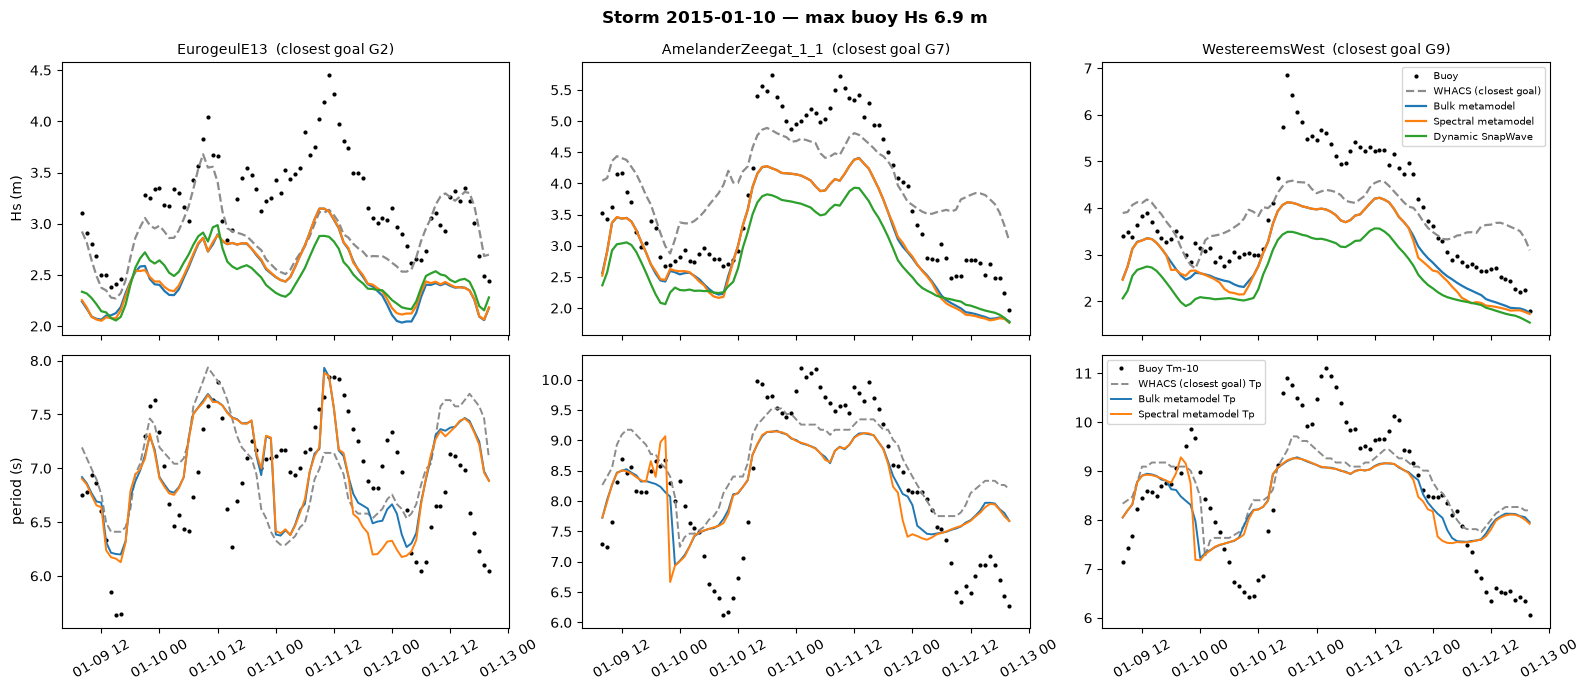

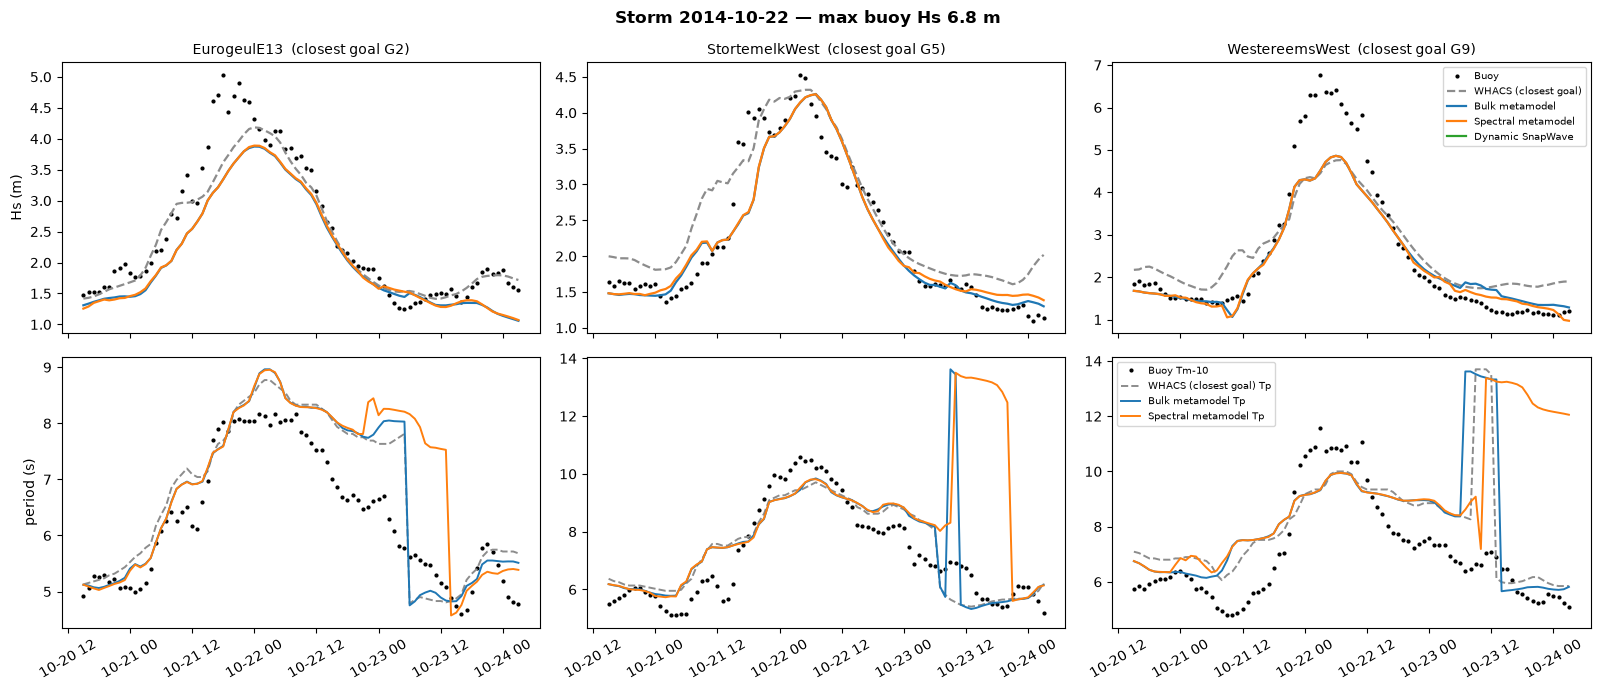

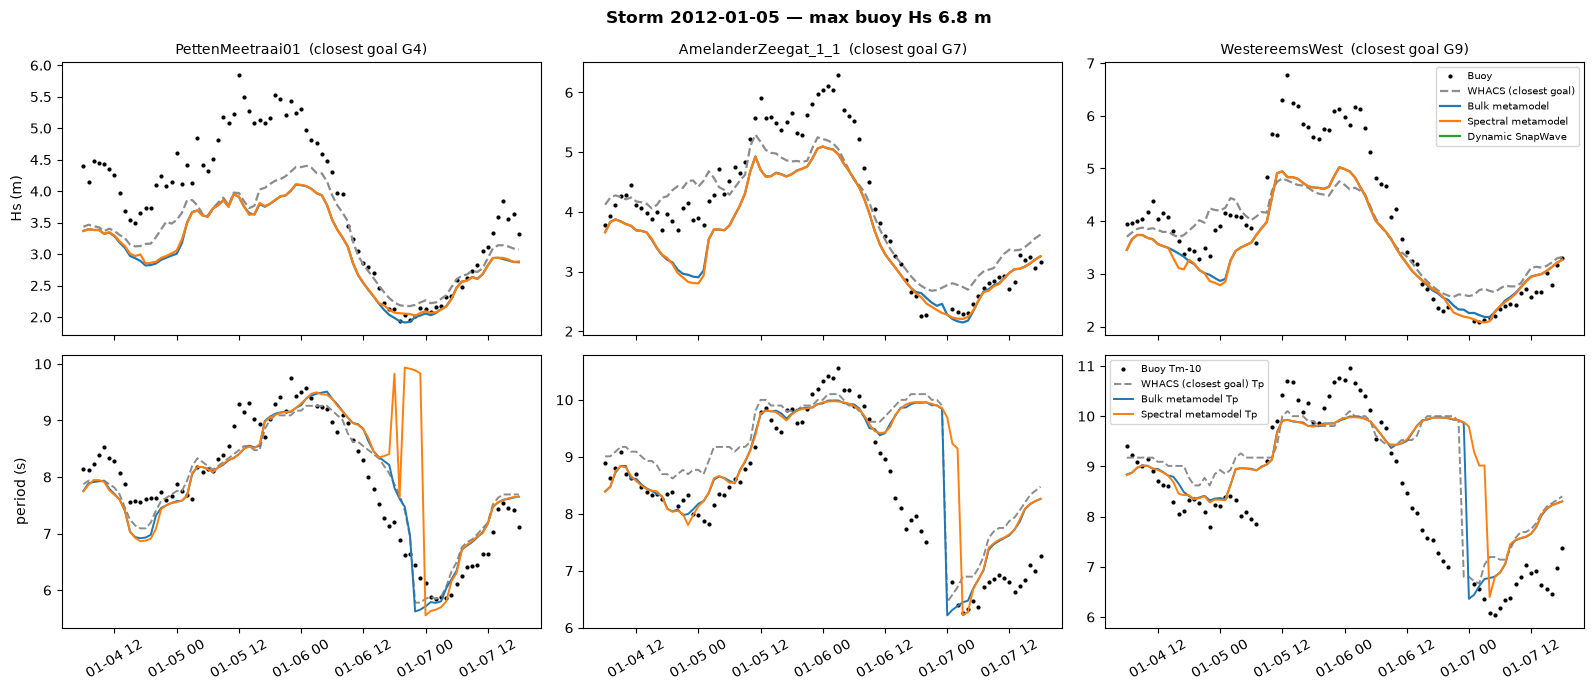

In [ ]:
for sid, st in storms.iterrows():
    tw = slice(st.time - plot_window[0], st.time + plot_window[1])
    seen = [b for b in analysis_buoys if b in set(p.loc[p.storm == sid, "buoy"])]
    show_buoys = [seen[i] for i in sorted({0, len(seen) // 2, len(seen) - 1})]
    fig, axes = plt.subplots(2, len(show_buoys), figsize=(16, 7), sharex=True)
    for j, b in enumerate(show_buoys):
        ax = axes[0, j]
        ax.plot(obs_hs[b][tw], ".", color=colors["Buoy"], ms=4, label="Buoy")
        for name, df in sources.items():
            ax.plot(
                df[b][tw],
                color=colors[name],
                lw=1.6,
                ls="--" if name.startswith("WHACS") else "-",
                label=name,
            )
        goal = int(closest_goals.set_index("site").loc[f"buoy_{b}", "goal"])
        ax.set_title(f"{b}  (closest goal G{goal})", fontsize=10)
        ax = axes[1, j]
        if b in obs_tm10:
            ax.plot(
                obs_tm10[b][tw], ".", color=colors["Buoy"], ms=4, label="Buoy Tm-10"
            )
        for name, df in source_tp.items():
            ax.plot(
                df[b][tw],
                color=colors[name],
                lw=1.4,
                ls="--" if name.startswith("WHACS") else "-",
                label=f"{name} Tp",
            )
        ax.tick_params(axis="x", rotation=30)
    axes[0, 0].set_ylabel("Hs (m)")
    axes[1, 0].set_ylabel("period (s)")
    axes[0, -1].legend(fontsize=7)
    axes[1, -1].legend(fontsize=7)
    fig.suptitle(
        f"Storm {st.time:%Y-%m-%d} — max buoy Hs {st.max_hs:.1f} m", weight="bold"
    )
    plt.tight_layout()
    plt.show()

In [ ]:
# Peak scores for the top storms only
top = p[p["storm"].isin(storms.index)]
cols = ["buoy", "time", "Buoy", *sources]
top[cols].assign(**{f"{n} ratio": top[n] / top["Buoy"] for n in sources}).sort_values(
    ["time", "buoy"]
).round(2)

,buoy,time,Buoy,WHACS (closest goal),Bulk metamodel,Spectral metamodel,Dynamic SnapWave,WHACS (closest goal) ratio,Bulk metamodel ratio,Spectral metamodel ratio,Dynamic SnapWave ratio
183,PettenMeetraai01,2012-01-05 12:00:00,5.85,4.38,4.10,4.11,NaN,0.75,0.70,0.70,NaN
184,WestereemsWest,2012-01-05 13:00:00,6.78,4.81,5.02,5.02,NaN,0.71,0.74,0.74,NaN
185,EierlandseGat,2012-01-05 22:00:00,5.88,4.57,4.47,4.47,NaN,0.78,0.76,0.76,NaN
186,AmelanderZeegat_1_1,2012-01-06 03:00:00,6.30,5.25,5.09,5.10,NaN,0.83,0.81,0.81,NaN
332,EurogeulE13,2013-12-05 13:00:00,4.92,3.83,3.75,3.75,NaN,0.78,0.76,0.76,NaN
333,StortemelkWest,2013-12-05 21:00:00,4.85,5.35,5.16,5.18,NaN,1.10,1.06,1.07,NaN
334,AmelanderZeegat_1_1,2013-12-05 23:00:00,7.44,6.77,6.42,6.43,NaN,0.91,0.86,0.86,NaN
388,EurogeulE13,2014-10-21 18:00:00,5.04,4.18,3.87,3.89,NaN,0.83,0.77,0.77,NaN
389,IJmuidenMunitiestort_1,2014-10-22 01:00:00,5.89,4.22,4.34,4.34,NaN,0.72,0.74,0.74,NaN
390,WestereemsWest,2014-10-22 03:00:00,6.78,4.76,4.86,4.86,NaN,0.70,0.72,0.72,NaN


## 4 · Summary

496 storm peaks with buoy Hs > 3 m in 2010–2015, across 7 buoys.

| Source | Median peak ratio | Peak bias | Peak RMSE |
| --- | --- | --- | --- |
| WHACS (closest goal) | **0.90** | −0.41 m | 0.67 m |
| Bulk metamodel | **0.75** | −0.92 m | 1.04 m |
| Spectral metamodel | **0.75** | −0.92 m | 1.03 m |
| Dynamic SnapWave (2010 + 2015, 158 peaks) | **0.71** | −1.15 m | 1.27 m |

On the same 158 peaks the ranking does not change (WHACS 0.91, metamodels 0.75, dynamic 0.71).

- **Timing is fine.** Median Δt = 0 h for every source at every buoy (±1 h at most).
- **The reconstructions underestimate storm peaks by ~25 %** (≈ −0.9 m), fairly uniformly
  along the coast: 0.73 at Eurogeul up to 0.79–0.80 at Stortemelk/Westereems.
- **The WHACS boundary goals are already low at the peaks.** At the closest goal (30–55 km
  offshore, in deeper water) WHACS is ~10 % *below* the nearshore buoys, and the deficit grows
  with storm size: ratio ≈ 0.93 for 3–4 m peaks, ≈ 0.77 at 5–6 m, ≈ 0.70 at 6–7 m.
- **The rest is lost in the offshore → buoy transformation.** The metamodels drop another
  ~15 % below WHACS. The dynamic SnapWave run is as low as the metamodels (or lower), so the
  emulator is faithful and this loss is in the **SnapWave set-up**, not the GP/PCA. One likely
  cause: the SnapWave cases have no wind input, so the storm sea that keeps growing between the
  goal and the buoy is missing.
- **Bulk and spectral are identical at the peaks**, because WHACS has essentially one
  partition during storms.
- **Period:** in the big storms the buoys show Tm-10 of 11–13 s that the WHACS Tp (and hence
  the reconstruction) does not reach. Xaver (Dec 2013) is the clearest case: the long-period
  energy arrives at the buoys about a day before WHACS Tp jumps.

**Where to look next:** (1) WHACS storm peaks against an independent offshore reference
(platform buoys); (2) wind input or a storm-dependent correction in the SnapWave
transformation; (3) a simple peak/quantile bias correction as a pragmatic fix.
